In [1]:
import sys
import logging
from pathlib import Path

# PROJECT_SRC_PATH = '../../src'
PROJECT_SRC_PATH = '/p/projects/eubucco/git-eubucco/eubucco'
sys.path.append(PROJECT_SRC_PATH)

import preproc.create_release

# external libs
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely import wkt
import duckdb

%load_ext autoreload
%autoreload 2

In [2]:
import sys
print(sys.executable)

/home/floriann/.conda/envs/eubucco-features/bin/python


In [3]:


pd.set_option("display.max_columns", None)

logging.basicConfig(format='%(asctime)s | %(levelname)s : %(message)s', level=logging.INFO)

## Height & Floor Regression

### EU-wide Eval Metrics

In [5]:
import duckdb

con = duckdb.connect()
con.execute("INSTALL spatial; LOAD spatial;")

# Define confidence thresholds
H_CONF = 2.0
F_CONF = 1.5

query = f"""
SELECT     
    -- Height Metrics
    count(p.height_true) AS h_total,
    count(*) FILTER (WHERE (p.height_confidence_upper - p.height_confidence_lower) < {H_CONF} AND p.height_true IS NOT NULL) / count(p.height_true)::FLOAT AS h_share_conf,
    avg(abs(p.height_pred - p.height_true)) AS h_mae,
    avg(abs(p.height_pred - p.height_true)) FILTER (WHERE (p.height_confidence_upper - p.height_confidence_lower) < {H_CONF}) AS h_mae_conf,
    
    sqrt(avg(pow(p.height_pred - p.height_true, 2))) AS h_rmse,
    sqrt(avg(pow(p.height_pred - p.height_true, 2)) FILTER (WHERE (p.height_confidence_upper - p.height_confidence_lower) < {H_CONF})) AS h_rmse_conf,

    -- Microsoft Height Metrics (Only reading 2 columns from this source)
    count(*) FILTER (WHERE f.bldg_msft_height IS NOT NULL AND p.height_true IS NOT NULL) AS h_msft_total,
    avg(abs(f.bldg_msft_height - p.height_true)) AS h_msft_mae,
    sqrt(avg(pow(f.bldg_msft_height - p.height_true, 2))) AS h_msft_rmse,

    -- Floor Metrics
    count(p.floors_true) AS f_total,
    count(*) FILTER (WHERE (p.floors_confidence_upper - p.floors_confidence_lower) < {F_CONF} AND p.floors_true IS NOT NULL) / count(p.floors_true)::FLOAT AS f_share_conf,
    avg(abs(p.floors_pred - p.floors_true)) AS f_mae,
    avg(abs(p.floors_pred - p.floors_true)) FILTER (WHERE (p.floors_confidence_upper - p.floors_confidence_lower) < {F_CONF}) AS f_mae_conf,
    
    sqrt(avg(pow(p.floors_pred - p.floors_true, 2))) AS f_rmse,
    sqrt(avg(pow(p.floors_pred - p.floors_true, 2)) FILTER (WHERE (p.floors_confidence_upper - p.floors_confidence_lower) < {F_CONF})) AS f_rmse_conf

FROM read_parquet('/p/projects/eubucco/data/6-prediction/*.parquet') p
JOIN (
    SELECT id, bldg_msft_height 
    FROM read_parquet('/p/projects/eubucco/data/5-feature-engineering/*.parquet')
) f ON p.id = f.id
"""

reg_mae = con.execute(query).df()
reg_mae.round(2)

,h_total,h_share_conf,h_mae,h_mae_conf,h_rmse,h_rmse_conf,h_msft_total,h_msft_mae,h_msft_rmse,f_total,f_share_conf,f_mae,f_mae_conf,f_rmse,f_rmse_conf
0,24745273,0.84,1.43,1.23,2.35,1.74,12824553,2.29,3.24,10734280,0.99,0.47,0.45,0.77,0.69


In [6]:
reg_mae[['h_total', 'h_mae', 'h_rmse',
       'h_msft_total', 'h_msft_mae', 'h_msft_rmse', 'f_total', 
       'f_mae', 'f_rmse']].round(2).to_dict(orient='records')

[{'h_total': 24745273,
  'h_mae': 1.43,
  'h_rmse': 2.35,
  'h_msft_total': 12824553,
  'h_msft_mae': 2.29,
  'h_msft_rmse': 3.24,
  'f_total': 10734280,
  'f_mae': 0.47,
  'f_rmse': 0.77}]

In [4]:
query_h_bins = """
SELECT 
    CASE 
        WHEN height_true < 5 THEN '0-5m'
        WHEN height_true < 10 THEN '5-10m'
        WHEN height_true < 20 THEN '10-20m'
        ELSE '20m+' 
    END AS height_bin,
    count(*) AS sample_size,
    avg(abs(height_pred - height_true)) AS h_mae,
    sqrt(avg(pow(height_pred - height_true, 2))) AS h_rmse
FROM read_parquet('/p/projects/eubucco/data/6-prediction/*.parquet')
WHERE height_true IS NOT NULL
GROUP BY 1
ORDER BY min(height_true) ASC
"""

df_h_bins = con.execute(query_h_bins).df()
print("Height Metrics by Size Bin:")
df_h_bins.round(1)

Height Metrics by Size Bin:


,height_bin,sample_size,h_mae,h_rmse
0,0-5m,11834939,1.2,1.7
1,5-10m,10825390,1.2,1.6
2,10-20m,1940058,3.0,3.8
3,20m+,144886,11.7,18.1


In [68]:

query_specific_types = """
SELECT 
    -- If residential, use subtype; otherwise use general type
    COALESCE(
        CASE WHEN type_true = 'residential' THEN residential_type_true END, 
        type_true
    ) AS specific_type,
    count(height_true) AS h_count,
    avg(abs(height_pred - height_true)) AS h_mae,
    sqrt(avg(pow(height_pred - height_true, 2))) AS h_rmse,
    count(floors_true) AS f_count,
    avg(abs(floors_pred - floors_true)) AS f_mae,
    sqrt(avg(pow(floors_pred - floors_true, 2))) AS f_rmse
FROM read_parquet('/p/projects/eubucco/data/6-prediction/*.parquet')
WHERE type_true IS NOT NULL
GROUP BY 1
HAVING h_count > 100 OR f_count > 100
ORDER BY h_count DESC;
"""

df_types = con.execute(query_specific_types).df()
print("Metrics by Specific Building Type (including Residential Subtypes):")
df_types.sort_values('f_mae', ascending=True).round(1)

Metrics by Specific Building Type (including Residential Subtypes):


,specific_type,h_count,h_mae,h_rmse,f_count,f_mae,f_rmse
2,others,1586003,1.4,2.0,1222677,0.8,1.4
1,commercial,1841103,1.5,2.5,640577,1.1,1.9
0,residential,5247627,1.4,2.0,6744785,1.2,1.7
3,agricultural,308267,1.6,2.5,432618,1.8,2.1
8,semi-detached duplex house,1436,2.0,3.3,37222,1.9,2.1
4,detached single-family house,293229,1.6,2.2,123786,2.0,2.3
7,apartment block,4833,4.0,7.9,70275,2.4,2.9
6,public,110987,2.8,4.8,137159,2.4,2.9
9,terraced house,619,2.0,2.5,12185,2.4,2.7
5,industrial,192092,2.4,6.5,394655,2.5,3.0


### Country-specific Eval Metrics

In [ ]:
import duckdb

con = duckdb.connect()
con.execute("INSTALL spatial; LOAD spatial;")

# Define confidence thresholds
H_CONF = 2.0
F_CONF = 1.5

query = f"""
SELECT     
    left(region, 2) AS country,

    -- Height Metrics
    count(p.height_true) AS h_total,
    count(*) FILTER (WHERE (p.height_confidence_upper - p.height_confidence_lower) < {H_CONF} AND p.height_true IS NOT NULL) / count(p.height_true)::FLOAT AS h_share_conf,
    avg(abs(p.height_pred - p.height_true)) AS h_mae,
    avg(abs(p.height_pred - p.height_true)) FILTER (WHERE (p.height_confidence_upper - p.height_confidence_lower) < {H_CONF}) AS h_mae_conf,
    
    sqrt(avg(pow(p.height_pred - p.height_true, 2))) AS h_rmse,
    sqrt(avg(pow(p.height_pred - p.height_true, 2)) FILTER (WHERE (p.height_confidence_upper - p.height_confidence_lower) < {H_CONF})) AS h_rmse_conf,

    -- Microsoft Height Metrics (Only reading 2 columns from this source)
    avg(abs(f.bldg_msft_height - p.height_true)) AS h_msft_mae,
    sqrt(avg(pow(f.bldg_msft_height - p.height_true, 2))) AS h_msft_rmse,

    -- Floor Metrics
    count(p.floors_true) AS f_total,
    count(*) FILTER (WHERE (p.floors_confidence_upper - p.floors_confidence_lower) < {F_CONF} AND p.floors_true IS NOT NULL) / count(p.floors_true)::FLOAT AS f_share_conf,
    avg(abs(p.floors_pred - p.floors_true)) AS f_mae,
    avg(abs(p.floors_pred - p.floors_true)) FILTER (WHERE (p.floors_confidence_upper - p.floors_confidence_lower) < {F_CONF}) AS f_mae_conf,
    
    sqrt(avg(pow(p.floors_pred - p.floors_true, 2))) AS f_rmse,
    sqrt(avg(pow(p.floors_pred - p.floors_true, 2)) FILTER (WHERE (p.floors_confidence_upper - p.floors_confidence_lower) < {F_CONF})) AS f_rmse_conf

FROM read_parquet('/p/projects/eubucco/data/6-prediction/*.parquet') p
JOIN (
    SELECT id, bldg_msft_height 
    FROM read_parquet('/p/projects/eubucco/data/5-feature-engineering/*.parquet')
) f ON p.id = f.id

GROUP BY 1
HAVING h_total >= 2000 OR f_total >= 2000;
"""

country_reg = con.execute(query).df()
country_reg.round(1).sort_values(by='h_mae')

,country,h_total,h_share_conf,h_mae,h_mae_conf,h_rmse,h_rmse_conf,h_msft_mae,h_msft_rmse,f_total,f_share_conf,f_mae,f_mae_conf,f_rmse,f_rmse_conf
16,NL,1936510,0.9,0.9,0.8,1.5,1.1,1.9,2.5,3600,0.1,2.4,1.1,2.7,1.5
8,PL,2883739,0.9,1.2,1.0,1.9,1.4,2.0,3.2,212427,0.1,2.4,1.5,2.7,1.7
18,FR,8496974,0.9,1.3,1.2,1.9,1.6,1.6,2.3,4611286,1.0,0.5,0.5,0.8,0.7
21,EE,160675,0.9,1.5,1.4,2.4,2.0,NaN,NaN,216,0.1,4.9,0.6,5.4,1.1
20,SK,665169,0.7,1.6,1.3,2.5,1.7,3.8,5.8,683,0.1,2.9,0.9,3.3,1.5
25,DE,5567083,0.9,1.6,1.3,2.8,1.9,2.8,3.7,2081667,0.6,1.3,0.5,1.9,1.1
14,SI,219054,0.8,1.7,1.7,3.4,3.0,4.3,5.0,41383,1.0,0.6,0.5,0.9,0.7
22,BE,1610039,0.9,1.8,1.6,2.6,2.2,3.3,4.3,922,0.1,2.1,1.1,2.4,1.4
12,IT,2494125,0.7,1.9,1.5,2.8,2.2,2.6,3.6,15483,0.2,2.3,1.0,2.7,1.4
2,FI,26608,0.7,1.9,1.5,3.2,2.2,2.8,4.0,10474,0.7,1.2,0.4,1.9,0.7


In [ ]:
# Robustness check that regional-level metrics are consistent with country-level assessments
def weighted_mean(x):
    # Drop rows where either value or weight is NaN
    subset = x[['height_mae', 'n']].dropna()
    
    if subset['n'].sum() <= 0:
        return np.nan
        
    return np.average(subset['height_mae'], weights=subset['n'])

eval_metrics = gpd.read_parquet('/p/projects/eubucco/data/8-additional-files/prediction-eval-metrics.parquet')
eval_metrics.groupby('country').apply(weighted_mean).round(2).dropna().sort_values()

/p/tmp/floriann/anaconda/ipykernel_3600410/818291179.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  eval_metrics.groupby('country').apply(weighted_mean).round(2).dropna().sort_values()


country
NL    0.87
PL    1.21
FR    1.29
EE    1.50
SK    1.57
DE    1.58
SI    1.75
BE    1.75
IT    1.86
FI    1.87
CH    1.88
CZ    2.05
LU    2.08
AT    2.41
MT    3.02
dtype: float64

## Type & Residential Type Classification

## Country-specific Height & Floor Regression Eval Metrics

### EU-wide Eval Metrics

In [84]:
        # residential_type_pred as label_pred,
        # residential_type_true as label_true
        # CASE WHEN type_true = 'residential' THEN 'res' ELSE 'non-res' END AS label_true,
        # CASE WHEN type_pred = 'residential' THEN 'res' ELSE 'non-res' END AS label_pred
query = f"""
WITH base AS (
    SELECT 
        type_pred AS label_pred,
        type_true AS label_true
    FROM read_parquet('/p/projects/eubucco/data/6-prediction/*.parquet')
    WHERE type_true IS NOT NULL
),
class_stats AS (
    SELECT 
        label_true,
        COUNT(*) FILTER (WHERE label_true = label_pred) AS tp,
        COUNT(*) AS support,
        -- False Positives: predicted this class, but true label was something else
        (SELECT COUNT(*) FROM base b2 
         WHERE b2.label_pred = b1.label_true 
         AND b2.label_true != b1.label_true) AS fp,
        -- False Negatives: true label was this class, but predicted something else
        COUNT(*) FILTER (WHERE label_true != label_pred) AS fn
    FROM base b1
    GROUP BY label_true
),
metrics AS (
    SELECT 
        *,
        tp::DOUBLE / NULLIF(tp + fp, 0) AS precision,
        tp::DOUBLE / NULLIF(tp + fn, 0) AS recall
    FROM class_stats
)
SELECT 
    label_true,
    support,
    precision,
    recall,
    (2.0 * precision * recall) / NULLIF(precision + recall, 0) AS f1,
    AVG((2.0 * precision * recall) / NULLIF(precision + recall, 0)) OVER () AS macro_f1,
    SUM(tp) OVER () / SUM(support) OVER () AS micro_f1
FROM metrics
ORDER BY support DESC;
"""

df_metrics = con.execute(query).df()
df_metrics.round(2).to_dict(orient='records')
df_metrics.round(2)

,label_true,support,precision,recall,f1,macro_f1,micro_f1
0,residential,14898027,0.91,0.91,0.91,0.66,0.82
1,others,4366359,0.73,0.77,0.75,0.66,0.82
2,commercial,2727436,0.71,0.71,0.71,0.66,0.82
3,agricultural,1249855,0.61,0.65,0.63,0.66,0.82
4,industrial,838715,0.55,0.51,0.53,0.66,0.82
5,public,491946,0.64,0.32,0.43,0.66,0.82


In [ ]:
#         # CASE WHEN type_true = 'residential' THEN 'res' ELSE 'non-res' END AS label_true,
#         # CASE WHEN type_pred = 'residential' THEN 'res' ELSE 'non-res' END AS label_pred
#         # residential_type_pred as label_pred,
#         # residential_type_true as label_true
# query = f"""
# WITH base AS (
#     SELECT 
#         type_pred as label_pred,
#         type_true as label_true
#     FROM read_parquet('/p/projects/eubucco/data/6-prediction/*.parquet')
#     WHERE type_true IS NOT NULL
#     -- AND type_confidence >= 0.5 
# ),
# class_stats AS (
#     SELECT 
#         label_true,
#         count(*) FILTER (WHERE label_true = label_pred) AS tp,
#         count(*) AS support,
#         (SELECT count(*) FROM base b2 WHERE b2.label_pred = ANY_VALUE(b1.label_true) AND b2.label_true != ANY_VALUE(b1.label_true)) AS fp,
#         count(*) FILTER (WHERE label_true != label_pred) AS fn
#     FROM base b1
#     GROUP BY label_true
# ),
# per_class_f1 AS (
#     SELECT *,
#         (2.0 * tp) / NULLIF(2.0 * tp + fp + fn, 0) AS f1
#     FROM class_stats
# )
# SELECT 
#     label_true,
#     support,
#     round(f1, 3) AS class_f1,
#     round(avg(f1) OVER (), 3) AS macro_f1,
#     round(sum(tp) OVER () / sum(support) OVER (), 3) AS micro_f1
# FROM per_class_f1
# ORDER BY support DESC;
# """

# df_f1 = con.execute(query).df()
# df_f1

,label_true,support,class_f1,macro_f1,micro_f1
0,residential,14898027,0.910,0.659,0.823
1,others,4366359,0.747,0.659,0.823
2,commercial,2727436,0.710,0.659,0.823
3,agricultural,1249855,0.631,0.659,0.823
4,industrial,838715,0.526,0.659,0.823
5,public,491946,0.429,0.659,0.823


### Country-specific Eval Metrics

In [35]:
        # residential_type_pred as label_pred,
        # residential_type_true as label_true
        # CASE WHEN type_true = 'residential' THEN 'res' ELSE 'non-res' END AS label_true,
        # CASE WHEN type_pred = 'residential' THEN 'res' ELSE 'non-res' END AS label_pred
query = f"""
WITH base AS (
    SELECT 
        left(region, 2) AS country,
        type_pred as label_pred,
        type_true as label_true
    FROM read_parquet('/p/projects/eubucco/data/6-prediction/*.parquet')
    WHERE type_true IS NOT NULL
),
class_stats AS (
    SELECT 
        country,
        label_true,
        count(*) FILTER (WHERE label_true = label_pred) AS tp,
        count(*) AS support,
        (
            SELECT count(*) 
            FROM base b2 
            WHERE b2.country = ANY_VALUE(b1.country) 
              AND b2.label_pred = ANY_VALUE(b1.label_true) 
              AND b2.label_true != ANY_VALUE(b1.label_true)
        ) AS fp,
        count(*) FILTER (WHERE label_true != label_pred) AS fn
    FROM base b1
    GROUP BY country, label_true
),
per_class_f1 AS (
    SELECT *,
        (2.0 * tp) / NULLIF(2.0 * tp + fp + fn, 0) AS f1
    FROM class_stats
)
SELECT 
    country,
    label_true,
    support,
    f1 AS class_f1,
    avg(f1) OVER (PARTITION BY country) AS macro_f1_country,
    sum(tp) OVER (PARTITION BY country) / sum(support) OVER (PARTITION BY country) AS micro_f1_country
FROM per_class_f1
ORDER BY country, support DESC;
"""

df_f1 = con.execute(query).df()
df_f1.round(2)

,country,label_true,support,class_f1,macro_f1_country,micro_f1_country
0,AT,residential,100401,0.89,0.60,0.83
1,AT,others,44451,0.80,0.60,0.83
2,AT,agricultural,7289,0.55,0.60,0.83
3,AT,industrial,4907,0.53,0.60,0.83
4,AT,public,3818,0.66,0.60,0.83
...,...,...,...,...,...,...
174,UK,others,136084,0.74,0.69,0.93
175,UK,agricultural,32742,0.61,0.69,0.93
176,UK,commercial,27652,0.40,0.69,0.93
177,UK,industrial,21210,0.68,0.69,0.93


## Confidence Score Assessment

In [54]:
import duckdb

con = duckdb.connect()

BIN_SIZE = 0.5 

query = f"""
WITH height_data AS (
    -- Calculate interval width and error in one pass
    SELECT 
        (height_confidence_upper - height_confidence_lower) AS uncertainty,
        abs(height_pred - height_true) AS absolute_error,
        height_true
    FROM read_parquet('/p/projects/eubucco/data/6-prediction/*.parquet')
    WHERE height_true IS NOT NULL 
      AND height_confidence_upper IS NOT NULL 
      AND height_confidence_lower IS NOT NULL
      -- AND height_true < 15
      -- AND height_true > 5

),
binned_stats AS (
    -- Group into discrete bins based on uncertainty width
    SELECT 
        floor(uncertainty / {BIN_SIZE}) * {BIN_SIZE} AS conf_bin,
        avg(absolute_error) AS mae,
        count(*) AS sample_size,
        avg(height_true) AS avg_height_true 
    FROM height_data
    GROUP BY 1
)
SELECT 
    conf_bin,
    round(mae, 3) AS mae,
    sample_size,
    round(avg_height_true, 2) AS avg_height
FROM binned_stats
WHERE sample_size > 500  -- Filter out noise from sparse bins
ORDER BY conf_bin ASC;
"""

df_height_bins = con.execute(query).df()
df_height_bins

,conf_bin,mae,sample_size,avg_height
0,0.0,0.881,2390821,3.99
1,0.5,1.088,8721613,5.03
2,1.0,1.351,6398887,5.80
3,1.5,1.600,3326206,6.30
4,2.0,1.884,1655105,6.86
5,2.5,2.217,874030,7.55
6,3.0,2.584,497331,8.33
7,3.5,2.925,301350,9.12
8,4.0,3.275,191001,9.89
9,4.5,3.679,120491,10.71


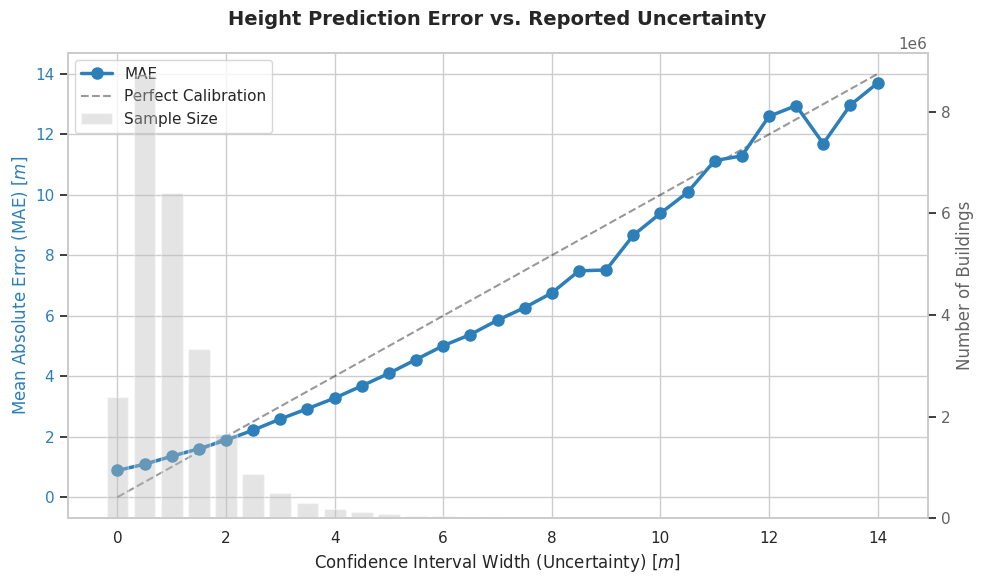

In [147]:
import seaborn as sns
# 2. Plotting Logic
sns.set_theme(style="whitegrid", palette="muted")
fig, ax1 = plt.subplots(figsize=(10, 6))

# Primary Axis: MAE
color_mae = '#2c7fb8'
ax1.set_xlabel('Confidence Interval Width (Uncertainty) $[m]$', fontsize=12)
ax1.set_ylabel('Mean Absolute Error (MAE) $[m]$', color=color_mae, fontsize=12)
line = ax1.plot(df_height_bins['conf_bin'], df_height_bins['mae'], marker='o', markersize=8, 
                linestyle='-', linewidth=2.5, color=color_mae, label='MAE', zorder=3)
ax1.tick_params(axis='y', labelcolor=color_mae)

# Reference Line: Perfect Calibration
ax1.plot([0, 14], [0, 14], linestyle='--', color='black', alpha=0.4, label='Perfect Calibration', zorder=1)

# Secondary Axis: Sample Size (Distribution)
ax2 = ax1.twinx()
color_bins = '#bdbdbd'
ax2.set_ylabel('Number of Buildings', color='#636363', fontsize=12)
bars = ax2.bar(df_height_bins['conf_bin'], df_height_bins['sample_size'], width=BIN_SIZE*0.8, 
               color=color_bins, alpha=0.4, label='Sample Size', zorder=1)
ax2.tick_params(axis='y', labelcolor='#636363')
ax2.grid(False) # Keep the grid clean

# 3. Aesthetics & Labels
plt.title('Height Prediction Error vs. Reported Uncertainty', fontsize=14, fontweight='bold', pad=20)

# Combine legends from both axes
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
leg = ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', frameon=True)

plt.tight_layout()
plt.savefig('/p/projects/eubucco/data/tmp/height_uncertainty.png', dpi=300)
plt.show()

### Type & Residential Type Classification

In [127]:
query_reliability = f"""
SELECT 
    count(*) FILTER (WHERE type_confidence IS NOT NULL) AS total_buildings,
    count(*) FILTER (WHERE type_confidence > 0.8) AS high_conf_count,
    round(avg((type_confidence > 0.8)::int), 3) AS share_above_08
FROM read_parquet('/p/projects/eubucco/data/6-prediction/*.parquet')
WHERE type_confidence IS NOT NULL AND type_true IS NOT NULL;
"""
con.execute(query_reliability).df()

,total_buildings,high_conf_count,share_above_08
0,24572338,16500979,0.672


In [134]:
CONF_BIN_SIZE = 0.1
query_reliability = f"""
WITH bin_stats AS (
    SELECT 
        floor(type_confidence / {CONF_BIN_SIZE}) * {CONF_BIN_SIZE} AS conf_bin,
        type_true,
        type_pred,
        count(*) as tally
    FROM read_parquet('/p/projects/eubucco/data/6-prediction/*.parquet')
    WHERE type_true IS NOT NULL AND type_confidence IS NOT NULL
    GROUP BY 1, 2, 3
),
metrics_per_class_per_bin AS (
    SELECT 
        conf_bin,
        type_true AS class_label,
        -- TP: True positive for this class
        sum(tally) FILTER (WHERE type_true = type_pred) AS tp,
        -- Support: Total actual instances of this class
        sum(tally) AS class_support,
        -- FP: Total times this class was predicted but was wrong
        (SELECT sum(tally) FROM bin_stats s2 
         WHERE s2.conf_bin = s1.conf_bin 
           AND s2.type_pred = s1.type_true 
           AND s2.type_true != s1.type_true) AS fp
    FROM bin_stats s1
    GROUP BY 1, 2
)
SELECT 
    conf_bin,
    -- Macro F1: Average of F1s per class
    round(avg((2.0 * tp) / NULLIF(2.0 * tp + (class_support - tp) + COALESCE(fp, 0), 0)), 3) AS macro_f1,
    -- Accuracy: Global TP / Global Support (Unique buildings)
    round(sum(tp) / sum(class_support), 3) AS accuracy,
    -- Correct unique building count
    sum(class_support) AS sample_size
FROM metrics_per_class_per_bin
GROUP BY 1
ORDER BY 1;
"""

df_reliability = con.execute(query_reliability).df()

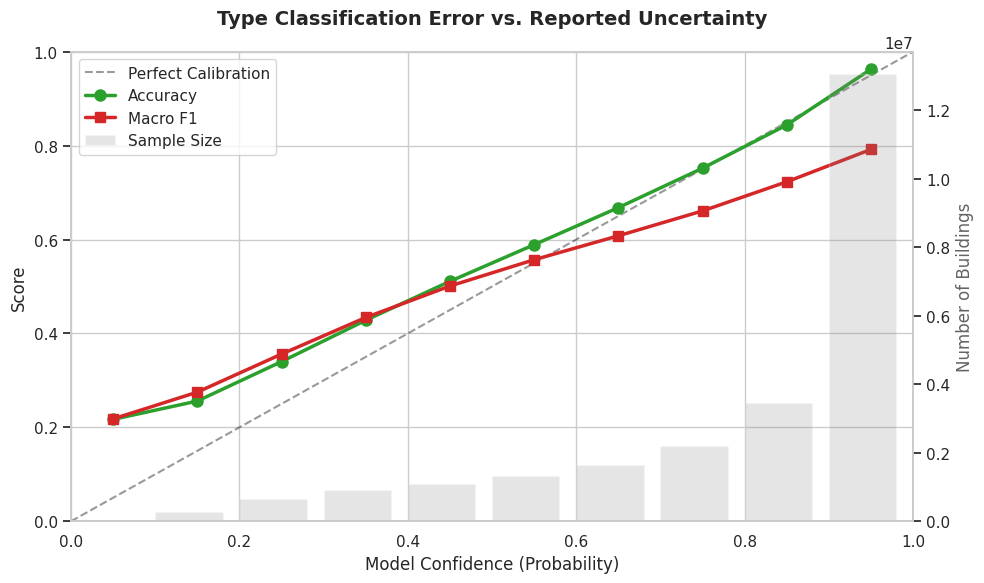

In [136]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(10, 6))

# Primary Axis: F1 Scores
color_acc = '#2ca02c' # Green
color_macro = '#d62728' # Red

# Reference Line: Perfect Calibration
ax1.plot([0, 1], [0, 1], linestyle='--', color='black', alpha=0.4, label='Perfect Calibration', zorder=1)

# Accuracy (Micro F1)
ax1.plot(df_reliability['conf_bin'] + 0.05, df_reliability['accuracy'], marker='o', 
         linewidth=2.5, markersize=8, color=color_acc, label='Accuracy', zorder=3)

# Macro F1
ax1.plot(df_reliability['conf_bin'] + 0.05, df_reliability['macro_f1'], marker='s', 
         linewidth=2.5, markersize=7, color=color_macro, label='Macro F1', zorder=4)

ax1.set_xlabel('Model Confidence (Probability)', fontsize=12)
ax1.set_ylabel('Score', fontsize=12)
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)

# Secondary Axis: Sample Size
ax2 = ax1.twinx()
ax2.bar(df_reliability['conf_bin'], df_reliability['sample_size'], width=0.08, 
        color='tab:gray', alpha=0.2, align='edge', label='Sample Size', zorder=2)
ax2.set_ylabel('Number of Buildings', color='#636363', fontsize=12)
ax2.grid(False)

plt.title('Type Classification Error vs. Reported Uncertainty', fontsize=14, fontweight='bold', pad=20)

# Combined Legend
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc='upper left', frameon=True)

fig.tight_layout()
plt.savefig('/p/projects/eubucco/data/tmp/type_uncertainty.png', dpi=300)
plt.show()

In [58]:
con = duckdb.connect()
CONF_BIN_SIZE = 0.1

query = f"""
WITH binned_raw AS (
    -- Group raw predictions into bins
    SELECT 
        floor(type_confidence / {CONF_BIN_SIZE}) * {CONF_BIN_SIZE} AS conf_bin,
        type_true,
        type_pred
    FROM read_parquet('/p/projects/eubucco/data/6-prediction/*.parquet')
    WHERE type_true IS NOT NULL AND type_confidence IS NOT NULL
),
bin_class_metrics AS (
    -- Calculate TP, FP, FN for every class INSIDE every bin
    SELECT 
        conf_bin,
        type_true AS class_label,
        count(*) FILTER (WHERE type_true = type_pred) AS tp,
        -- FP: Times this class was predicted but was actually something else
        (SELECT count(*) FROM binned_raw b2 
         WHERE b2.conf_bin = b1.conf_bin 
           AND b2.type_pred = b1.type_true 
           AND b2.type_true != b1.type_true) AS fp,
        -- FN: Times this was the true class but predicted as something else
        count(*) FILTER (WHERE type_true != type_pred) AS fn,
        count(*) AS support
    FROM binned_raw b1
    GROUP BY conf_bin, type_true
),
bin_f1_scores AS (
    -- Calculate per-class F1 per bin
    SELECT 
        conf_bin,
        (2.0 * tp) / NULLIF(2.0 * tp + fp + fn, 0) AS f1,
        support
    FROM bin_class_metrics
)
-- Aggregate to Macro F1 and total sample size per bin
SELECT 
    conf_bin,
    avg(f1) AS macro_f1,
    sum(support) AS sample_size
FROM bin_f1_scores
GROUP BY conf_bin
ORDER BY conf_bin ASC
"""

df_macro = con.execute(query).df()

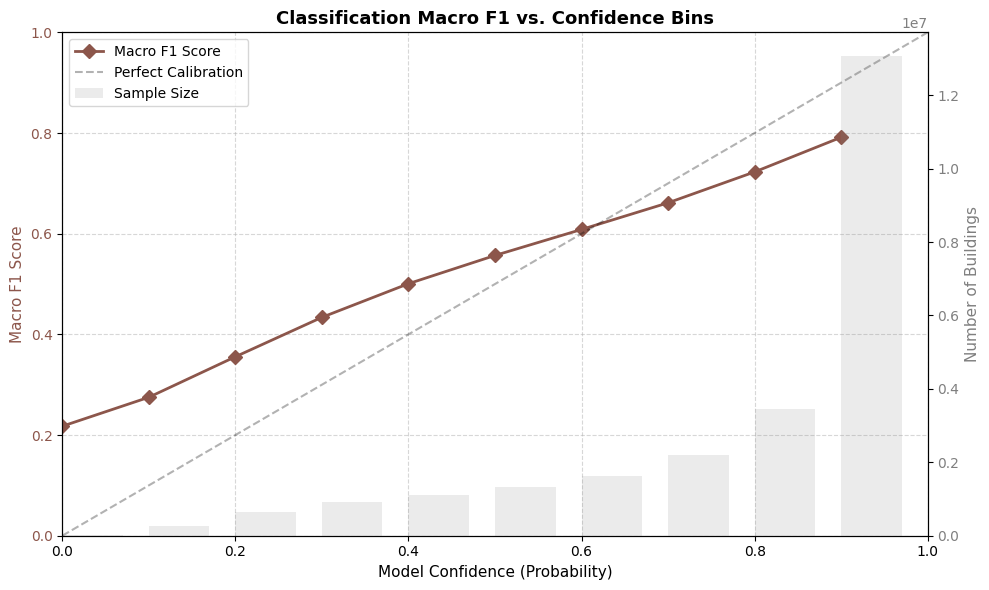

In [59]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Primary Axis: Macro F1
color_f1 = '#8c564b' # Brownish/Dark Red
ax1.plot(df_macro['conf_bin'], df_macro['macro_f1'], marker='D', 
         linewidth=2, markersize=7, color=color_f1, label='Macro F1 Score')

# Reference Line for Calibration
ax1.plot([0, 1], [0, 1], linestyle='--', color='black', alpha=0.3, label='Perfect Calibration')

ax1.set_xlabel('Model Confidence (Probability)', fontsize=11)
ax1.set_ylabel('Macro F1 Score', color=color_f1, fontsize=11)
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.tick_params(axis='y', labelcolor=color_f1)
ax1.grid(True, linestyle='--', alpha=0.5)

# Secondary Axis: Sample Size
ax2 = ax1.twinx()
color_samples = '#7f7f7f'
ax2.bar(df_macro['conf_bin'], df_macro['sample_size'], width=CONF_BIN_SIZE*0.7, 
        color=color_samples, alpha=0.15, align='edge', label='Sample Size')

ax2.set_ylabel('Number of Buildings', color=color_samples, fontsize=11)
ax2.tick_params(axis='y', labelcolor=color_samples)

plt.title('Classification Macro F1 vs. Confidence Bins', fontsize=13, fontweight='bold')

# Legend
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc='upper left')

fig.tight_layout()
plt.show()